# Plotting the quantities that `goldsluice` processed

*A second example for the `goldpan` / `goldsluice` note. Draft prepared with Claude Code for A. Villano, 2026-10-27.*

`goldsluice` reads the raw dumps of a series, computes quantities for every event and writes them as a `goldpan` Parquet dataset: one file per dump, plus `_goldpan.json` (the detector and its channels) and `_goldsluice.json` (what was run, with what, and how long it took). This notebook reads such a dataset back with `goldpan` and plots what is in it. It never touches the raw data.

**The data.** The example run of `goldsluice/examples/r76.dataset.toml` on the real Run 76 series `07221203_2025` (Side-2 readout, 30 dumps, 81,992 events), written to `goldsluice/examples/processed/r76-07221203/`. That folder is not in the repository (it is the output of a run, about 6 MB); to make it, run `python -m goldsluice run r76.dataset.toml` in `goldsluice/examples/`. Only the algorithm `peak` has run so far, so each of the six phonon channels has two quantities:

- `adc_max`: the largest ADC value of the trace (counts);
- `current_max`: the largest value above the pretrigger baseline. It is still in **ADC counts**: the conversion to amps (`amps_per_adc` in the dataset file) is a placeholder equal to 1 until the ADC-to-amps scale is known, so the axis labels below say counts.

Needs `goldpan` (installed by `requirements.txt`). Run with the `darkmatter_cli_env` kernel.

In [1]:
import json
from pathlib import Path

import awkward as ak
import matplotlib.pyplot as plt
import numpy as np

from goldpan import adapters

In [2]:
# Find the processed dataset by walking up to the repository's goldsluice/examples folder.
_here = Path.cwd().resolve()
EXAMPLES = next(p / "goldsluice" / "examples" for p in [_here, *_here.parents] if (p / "goldsluice" / "examples").is_dir())
DATASET = EXAMPLES / "processed" / "r76-07221203"
assert DATASET.exists(), f"{DATASET} is missing: run `python -m goldsluice run r76.dataset.toml` in {EXAMPLES}"

events = adapters.read(DATASET)               # every dump of the folder, joined; the format is guessed from the folder
q = events.quantities                         # one record per event: series, dump, event, then one record per channel
channels = list(events.detector.channel_names())

print(events)
print("channels:", channels)
print("quantities of one channel:", ak.fields(q[channels[0]]))
print("dumps:", len(np.unique(ak.to_numpy(q["dump"]))), "from", ak.to_numpy(q["dump"])[0], "to", ak.to_numpy(q["dump"])[-1])

Events(detector='NAI-S2', n_events=81992, traces=[], quantities=['series', 'dump', 'event', 'Side2pC', 'Side2pF', 'Side2pE', 'Side2pB', 'Side2pA', 'Side2pD'])
channels: ['Side2pC', 'Side2pF', 'Side2pE', 'Side2pB', 'Side2pA', 'Side2pD']
quantities of one channel: ['adc_max', 'current_max']
dumps: 30 from F0001 to F0030


In [3]:
# What goldsluice says about the run that made these files.
log = json.loads((DATASET / "_goldsluice.json").read_text())
runs = log["files"]
total = {k: sum(r["seconds"].get(k, 0) for r in runs.values()) for k in ("read", "peak", "write")}
print(len(runs), "dumps processed;", sum(r["n_events"] for r in runs.values()), "events")
print("time spent (s): " + ", ".join(f"{k} {v:.1f}" for k, v in total.items()))
print("(reading the raw dumps costs far more than computing the quantity)")

30 dumps processed; 81992 events
time spent (s): read 108.6, peak 1.2, write 2.9
(reading the raw dumps costs far more than computing the quantity)


In [4]:
# Put the quantities in plain arrays: one array per channel and quantity.
adc_max = {ch: ak.to_numpy(q[ch]["adc_max"]) for ch in channels}
cur_max = {ch: ak.to_numpy(q[ch]["current_max"]) for ch in channels}
dump = ak.to_numpy(q["dump"])
event = ak.to_numpy(q["event"])

for ch in channels:
    c = cur_max[ch]
    print(f"{ch}: current_max median {np.median(c):6.2f}, 99th percentile {np.percentile(c, 99):7.1f}, largest {c.max():8.1f}")

Side2pC: current_max median 110.77, 99th percentile   315.3, largest   4946.2
Side2pF: current_max median 209.35, 99th percentile   553.7, largest    689.0
Side2pE: current_max median 143.44, 99th percentile   391.9, largest    510.1
Side2pB: current_max median 329.75, 99th percentile   774.1, largest  31220.1
Side2pA: current_max median 449.48, 99th percentile   994.6, largest  31665.3
Side2pD: current_max median 250.89, 99th percentile   622.3, largest    764.2


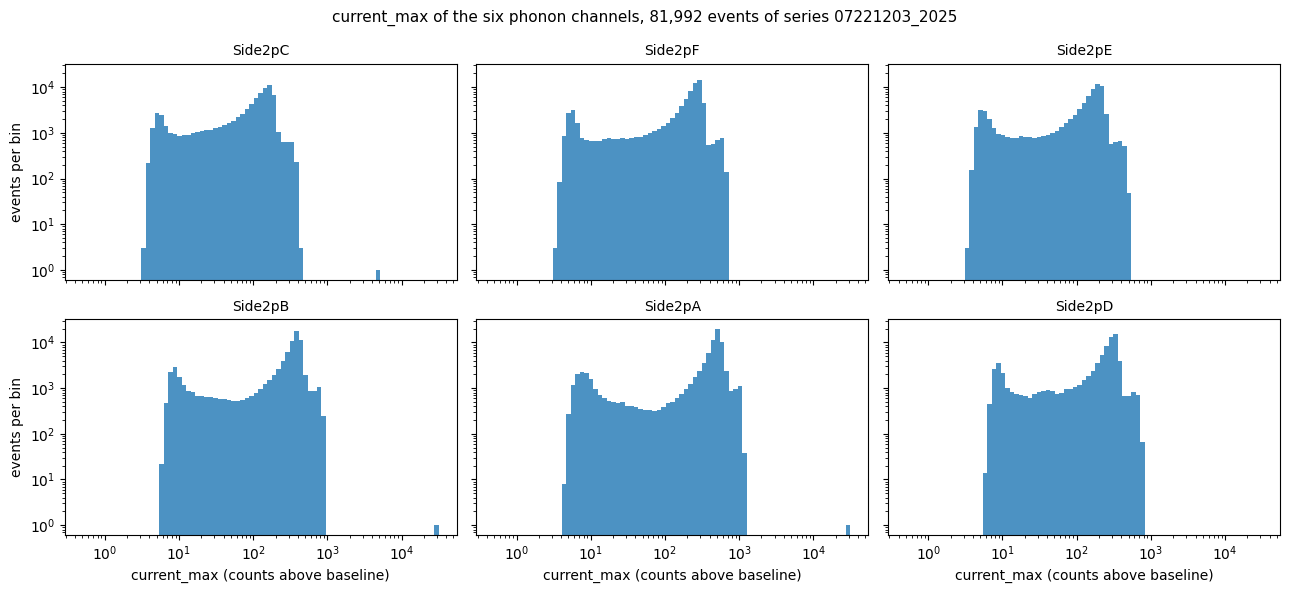

In [5]:
# The distribution of current_max, all six channels. A log axis shows the tail of large pulses over the noise.
bins = np.logspace(np.log10(0.5), np.log10(max(c.max() for c in cur_max.values())), 80)
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True, sharey=True)
for ax, ch in zip(axes.flat, channels):
    ax.hist(np.clip(cur_max[ch], bins[0], None), bins=bins, color="C0", alpha=0.8)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(ch, fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("current_max (counts above baseline)")
for ax in axes[:, 0]:
    ax.set_ylabel("events per bin")
fig.suptitle(f"current_max of the six phonon channels, {len(q):,} events of series 07221203_2025", fontsize=11)
fig.tight_layout()
plt.show()

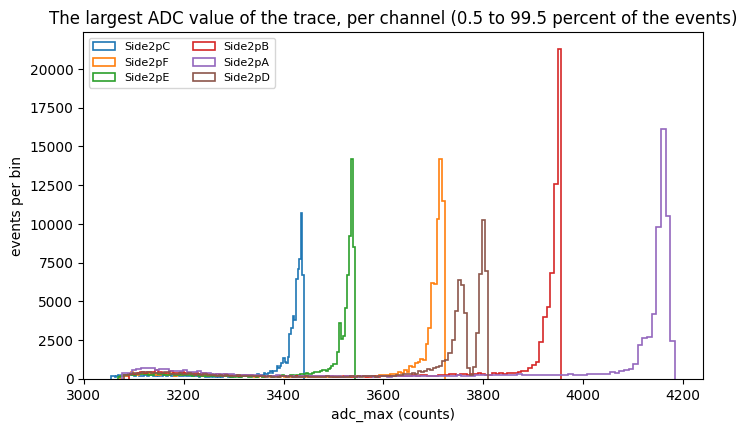

In [6]:
# adc_max, the raw maximum, tells the baseline level of each channel (current_max is measured from it).
fig, ax = plt.subplots(figsize=(8, 4.5))
for ch in channels:
    lo, hi = np.percentile(adc_max[ch], [0.5, 99.5])
    ax.hist(adc_max[ch], bins=np.linspace(lo, hi, 120), histtype="step", lw=1.2, label=ch)
ax.set_xlabel("adc_max (counts)")
ax.set_ylabel("events per bin")
ax.set_title("The largest ADC value of the trace, per channel (0.5 to 99.5 percent of the events)")
ax.legend(fontsize=8, ncol=2)
plt.show()

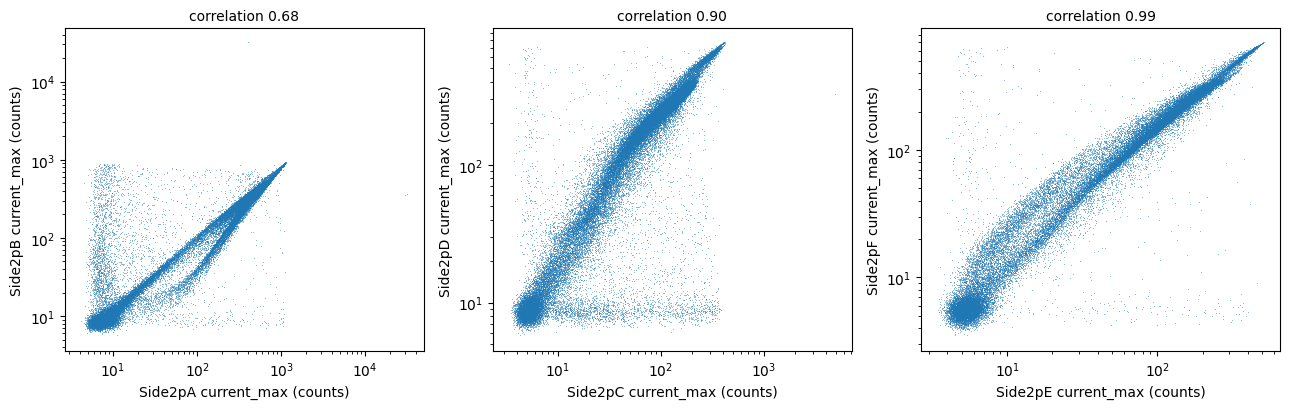

In [7]:
# Do the channels see the same pulses? current_max of one channel against another, and the size of the biggest pulses.
pairs = [("Side2pA", "Side2pB"), ("Side2pC", "Side2pD"), ("Side2pE", "Side2pF")]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (a, b) in zip(axes, pairs):
    ax.plot(np.clip(cur_max[a], 0.5, None), np.clip(cur_max[b], 0.5, None), ",", color="C0", alpha=0.5)
    ax.set_xscale("log")
    ax.set_yscale("log")
    r = np.corrcoef(cur_max[a], cur_max[b])[0, 1]
    ax.set_xlabel(f"{a} current_max (counts)")
    ax.set_ylabel(f"{b} current_max (counts)")
    ax.set_title(f"correlation {r:.2f}", fontsize=10)
fig.tight_layout()
plt.show()

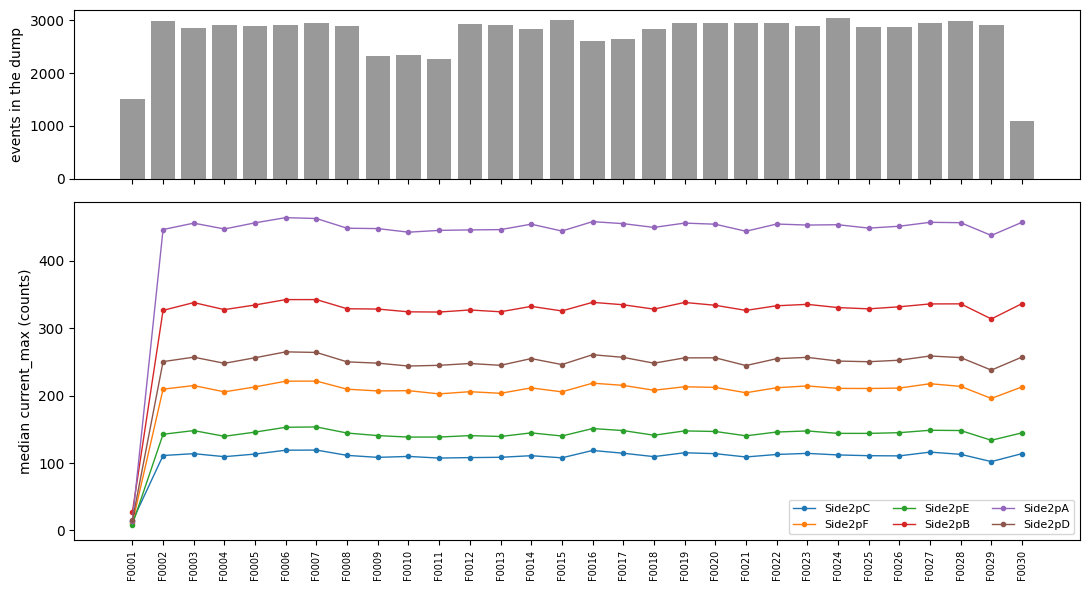

In [8]:
# A quantity per dump: how many events each dump holds, and the median current_max of every channel as the series goes on.
dumps = np.array(sorted(set(dump)))
n_per_dump = np.array([(dump == d).sum() for d in dumps])
x = np.arange(len(dumps))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
ax1.bar(x, n_per_dump, color="0.6")
ax1.set_ylabel("events in the dump")
for ch in channels:
    ax2.plot(x, [np.median(cur_max[ch][dump == d]) for d in dumps], "o-", ms=3, lw=1, label=ch)
ax2.set_ylabel("median current_max (counts)")
ax2.set_xticks(x)
ax2.set_xticklabels(dumps, rotation=90, fontsize=7)
ax2.legend(fontsize=8, ncol=3)
fig.tight_layout()
plt.show()

In [9]:
# The largest pulse in each channel: which event, and what the other channels saw in it.
for ch in channels:
    i = int(np.argmax(cur_max[ch]))
    others = "  ".join(f"{o} {cur_max[o][i]:7.1f}" for o in channels)
    print(f"{ch}: dump {dump[i]}, event {event[i]}, current_max {cur_max[ch][i]:8.1f} | {others}")

Side2pC: dump F0014, event 10716, current_max   4946.2 | Side2pC  4946.2  Side2pF   275.8  Side2pE   181.9  Side2pB   361.6  Side2pA   435.5  Side2pD   321.1
Side2pF: dump F0017, event 10850, current_max    689.0 | Side2pC   421.1  Side2pF   689.0  Side2pE   510.1  Side2pB   904.9  Side2pA  1126.0  Side2pD   738.3
Side2pE: dump F0017, event 10850, current_max    510.1 | Side2pC   421.1  Side2pF   689.0  Side2pE   510.1  Side2pB   904.9  Side2pA  1126.0  Side2pD   738.3
Side2pB: dump F0024, event 13807, current_max  31220.1 | Side2pC   135.7  Side2pF   263.3  Side2pE   163.9  Side2pB 31220.1  Side2pA   403.6  Side2pD   326.1
Side2pA: dump F0006, event 11869, current_max  31665.3 | Side2pC   130.9  Side2pF   235.5  Side2pE   167.5  Side2pB   354.5  Side2pA 31665.3  Side2pD   286.7
Side2pD: dump F0005, event 10654, current_max    764.2 | Side2pC   417.6  Side2pF   686.6  Side2pE   507.5  Side2pB   898.6  Side2pA  1153.1  Side2pD   764.2


**What this shows, and what is next.** `adapters.read` on the output folder gives the quantities of all dumps as one `Events`, one record per event, with a record of quantities for each channel. Plots of it are ordinary `numpy` and `matplotlib`. The same folder reads back with `goldpan.dataset` or with `pyarrow` directly, since it is plain Parquet.

Not done here: the amps (`current_max` is in counts until the ADC-to-amps scale is known), cuts, and the traces. To look at a trace next to its quantities, read the raw dump (or its Parquet copy) with `adapters.read` and join the quantities by `series`, `dump` and `event` as in `rq-histogram-goldpan.ipynb`. More quantities will appear here as `goldsluice` gets more algorithms: each is one more field in every channel's record.